In [23]:
"""
STEP 1: Load All OpenFOAM Cases
==================================
Extracts velocity profiles from all configurations and saves to pickle file.
Includes outlier detection and conservative filtering at problematic points.
"""

from setup_paths import SRC_DIR, DATA_DIR, RAW_DATA_DIR, PROCESSED_DATA_DIR, FIGURES_DIR 
import sys
import numpy as np
import pickle
import os
import matplotlib.pyplot as plt 

from OpenFOAM_reader import extract_profile_from_openfoam




In [10]:
# ============================================
# CONFIGURATION
# ============================================

# Definition of the cases (8 for now)
CASES = {
    'U1_uniform': {
        'path': RAW_DATA_DIR / 'Cube_SIMPLE_kOmegaSST_Uprofile_4_Uniform_U1',  
        'U_ref': 1.0,
        'profile_type': 0,                  # 0=uniform, 1=ABL+const, 2=ABL+free, 3=ABL+lam
        'profile_name': 'Uniform',
        'description': 'Uniform inlet, U_ref=1 m/s'
    },
    'U1_ABL_const': {
        'path': RAW_DATA_DIR / 'Cube_SIMPLE_kOmegaSST_Uprofile_5_ABLc_U1',  
        'U_ref': 1.0,
        'profile_type': 1,
        'profile_name': 'ABL+constant',
        'description': 'ABL+constant no-slip top, U_ref=1 m/s'
    },
    'U1_ABL_lam': {
        'path': RAW_DATA_DIR / 'Cube_SIMPLE_kOmegaSST_Uprofile_6_ABLcLam_U1', 
        'U_ref': 1.0,
        'profile_type': 3,
        'profile_name': 'ABL+laminar',
        'description': 'ABL+constant+laminar turbulence layer, U_ref=1 m/s'
    },
    'U1_ABL_free': {
        'path': RAW_DATA_DIR / 'Cube_SIMPLE_kOmegaSST_Uprofile_7_ABLfreeTop_U1', 
        'U_ref': 1.0,
        'profile_type': 2,
        'profile_name': 'ABL+free',
        'description': 'ABL+free top, U_ref=1 m/s'
    },
    'U5_uniform': {
        'path': RAW_DATA_DIR / 'Cube_SIMPLE_kOmegaSST_Uprofile_8_Uniform_U5', 
        'U_ref': 5.1,
        'profile_type': 0,
        'profile_name': 'Uniform',
        'description': 'Uniform inlet, U_ref=5.1 m/s'
    },
    'U5_ABL_const': {
        'path': RAW_DATA_DIR / 'Cube_SIMPLE_kOmegaSST_Uprofile_9_ABLc_U5',  
        'U_ref': 5.1,
        'profile_type': 1,
        'profile_name': 'ABL+constant',
        'description': 'ABL+constant no-slip top, U_ref=5.1 m/s'
    },
    'U5_ABL_lam': {
        'path': RAW_DATA_DIR / 'Cube_SIMPLE_kOmegaSST_Uprofile_10_ABLcLam_U5_coded',  
        'U_ref': 5.1,
        'profile_type': 3,
        'profile_name': 'ABL+laminar',
        'description': 'ABL+constant+laminar turbulence layer, U_ref=5.1 m/s'
    },
    'U5_ABL_free': {
        'path': RAW_DATA_DIR / 'Cube_SIMPLE_kOmegaSST_Uprofile_11_ABLfreeTop_U5',   
        'U_ref': 5.1,
        'profile_type': 2,
        'profile_name': 'ABL+free',
        'description': 'ABL+free top, U_ref=5.1 m/s'
    },
}

# X-locations for profile extraction
X_LOCATIONS = np.array([
    0.0000000,      # Inlet
    0.0375000,      # Non-disturbed flow
    0.0650000,      # In front of the cube
    0.0750000,      # Front face of the cube
    0.0825000,      # Top mid of the cube
    0.0903125,      # Just behind the cube
    0.1050000,      # Near wake:    1*Hc
    0.1200000,      # Further Wake: 2*Hc
    0.1350000,      # Further Wake: 3*Hc
    0.1500000,      # Far wake:     4*Hc
    0.3150000       # Outlet
])

# OpenFOAM extraction settings
TIME = 'latestTime'                  # Solution time: '10000', '2', 'latestTime' 
Y_LOCATION = None                    # Centerplane
TOLERANCE = 0.0012500                # 0.0012500 = coarse mesh dx
METHOD = 'closest'
N_BINS = 100

# Cube geometry (for reference)
H_CUBE = 0.015  # meters
X_CUBE_FRONT = 0.075
X_CUBE_BACK = 0.090

# Outlier filtering settings
ENABLE_OUTLIER_FILTERING = True
OUTLIER_THRESHOLD_SIGMA = 3.0        # Standard deviations for local smoothness
OUTLIER_THRESHOLD_GRADIENT = 5.0     # Multiplier for gradient spikes
OUTLIER_WINDOW_SIZE = 3              # Neighbors to check
OUTLIER_CHECK_ALL_LOCATIONS = True   # If False, only check PROBLEM_X_LOCATIONS
PROBLEM_X_LOCATIONS = [0.0750000, 0.0825000, 0.0903125, 0.1050000]  # Known problematic locations (cube region)

RAW_DATA_FILE = PROCESSED_DATA_DIR / 'all_cases_data_noisy.pkl' 
FILTERED_DATA_FILE = PROCESSED_DATA_DIR / 'all_cases_data.pkl'
FILTERING_REPORT_FILE = PROCESSED_DATA_DIR / 'outlier_filtering_report.pkl'
FILTERING_VIZ_FILE = PROCESSED_DATA_DIR / 'step1_outlier_filtering.png'


In [3]:
# ============================================
# MAIN LOADING FUNCTION
# ============================================

def load_all_cases():
    """
    Load all CFD cases and extract velocity profiles
    
    Returns:
        dict: all_cases_data with structure:
            {
                'case_id': {
                    'profiles': {x_loc: {'z': ..., 'U_x': ..., ...}},
                    'U_ref': float,
                    'profile_type': int,
                    'profile_name': str,
                    'description': str,
                    'path': str
                }
            }
    """
    
    all_cases_data = {}
    
    print("="*80)
    print("LOADING ALL OPENFOAM CASES")
    print("="*80)
    print(f"Total cases to load: {len(CASES)}")
    print(f"Profiles per case: {len(X_LOCATIONS)}")
    print(f"Expected total profiles: {len(CASES) * len(X_LOCATIONS)}")
    print("="*80 + "\n")
    
    for case_id, case_info in CASES.items():
        print("\n" + "="*80)
        print(f"CASE: {case_id}")
        print("="*80)
        print(f"Description: {case_info['description']}")
        print(f"Path: {case_info['path']}")
        print(f"U_ref: {case_info['U_ref']} m/s")
        print(f"Profile type: {case_info['profile_type']} ({case_info['profile_name']})")
        
        # Check if case directory exists
        if not os.path.exists(case_info['path']):
            print(f"⚠️  WARNING: Directory does not exist! Skipping...")
            continue
        
        print("-"*80)
        
        # Extract profiles at all x-locations
        profiles = {}
        success_count = 0
        fail_count = 0
        
        for x_loc in X_LOCATIONS:
            print(f"  x = {x_loc:.6f} m ... ", end='', flush=True)
            
            try:
                z_prof, Ux_prof, Uy_prof, Uz_prof = extract_profile_from_openfoam(
                    case_path=case_info['path'],
                    x_location=x_loc,
                    time=TIME,
                    y_location=Y_LOCATION,
                    tolerance=TOLERANCE,
                    method=METHOD,
                    n_bins=N_BINS
                )
                
                if z_prof is not None and len(z_prof) > 0:
                    profiles[x_loc] = {
                        'z': z_prof,
                        'U_x': Ux_prof,
                        'U_y': Uy_prof,
                        'U_z': Uz_prof,
                        'n_points': len(z_prof)
                    }
                    print(f"✓ ({len(z_prof)} points)")
                    success_count += 1
                else:
                    print(f"✗ FAILED (no data)")
                    fail_count += 1
                    
            except Exception as e:
                print(f"✗ ERROR: {str(e)}")
                fail_count += 1
        
        # Store case data
        all_cases_data[case_id] = {
            'profiles': profiles,
            'U_ref': case_info['U_ref'],
            'profile_type': case_info['profile_type'],
            'profile_name': case_info['profile_name'],
            'description': case_info['description'],
            'path': case_info['path'],
            'n_profiles_extracted': success_count,
        }
        
        print("-"*80)
        print(f"✓ Case loaded: {success_count}/{len(X_LOCATIONS)} profiles extracted")
        if fail_count > 0:
            print(f"⚠️  {fail_count} profiles failed")
    
    return all_cases_data



In [25]:
# ============================================
# OUTLIER DETECTION & FILTERING FUNCTIONS
# ============================================

def detect_velocity_outliers(z, U, window=5, threshold=3.0):
    """
    Detect points that violate local smoothness.
    
    For each point, check if it deviates from neighbors by >threshold std.
    """
    outliers = []
    
    for i in range(window, len(U) - window):
        # Get neighbors (excluding point itself)
        neighbors = np.concatenate([U[i-window:i], U[i+1:i+window+1]])
        
        # Local statistics
        local_mean = np.mean(neighbors)
        local_std = np.std(neighbors)
        
        # Check deviation
        if local_std > 1e-10:  # Avoid division by zero
            deviation = np.abs(U[i] - local_mean)
            
            if deviation > threshold * local_std:
                outliers.append(i)
    
    return outliers

def detect_gradient_spikes(z, U, threshold=5.0):
    """
    Detect sharp changes in velocity gradient.
    """
    if len(U) < 3:
        return []
    
    dU_dz = np.gradient(U, z)
    
    # Second derivative (curvature)
    d2U_dz2 = np.gradient(dU_dz, z)
    
    # Find spikes in second derivative
    median_curv = np.median(np.abs(d2U_dz2))
    if median_curv > 1e-10:
        outliers = np.where(np.abs(d2U_dz2) > threshold * median_curv)[0]
        return outliers.tolist()
    return []

def detect_physical_violations(z, U, U_ref, H_cube=0.015):
    """
    Check for physically impossible values.
    """
    outliers = []
    
    for i, (z_i, U_i) in enumerate(zip(z, U)):
        # Check 1: Velocity way too high (>2× reference)
        if U_i > 2.0 * U_ref:
            outliers.append(i)
        
        # Check 2: Recirculation zone shouldn't have very high positive velocity
        if z_i < H_cube and U_i > 0.5 * U_ref:
            # Check neighbors
            if i > 0 and i < len(U) - 1:
                if U[i-1] < 0 and U[i+1] < 0:  # Surrounded by negative
                    outliers.append(i)
    
    return outliers

def filter_outliers_interpolation(z, U, outlier_indices):
    """
    Replace outliers with interpolated values from neighbors.
    """
    if len(outlier_indices) == 0:
        return U
    
    U_filtered = U.copy()
    
    for idx in sorted(outlier_indices):
        # Find nearest non-outlier neighbors
        left = idx - 1
        right = idx + 1
        
        while left in outlier_indices and left > 0:
            left -= 1
        while right in outlier_indices and right < len(U) - 1:
            right += 1
        
        # Linear interpolation between neighbors
        if left >= 0 and right < len(U):
            z_left, z_right = z[left], z[right]
            U_left, U_right = U[left], U[right]
            
            # Interpolate
            U_filtered[idx] = U_left + (U_right - U_left) * (z[idx] - z_left) / (z_right - z_left)
    
    return U_filtered


def detect_and_filter_profile(z, U, U_ref, x_loc, case_id, 
                               window=3, threshold_sigma=3.0, threshold_grad=5.0):
    """
    Detect and filter outliers in a single profile.
    
    Returns:
        U_filtered: Filtered velocity profile
        n_outliers: Number of outliers detected
        outlier_info: Dict with detailed information
    """
    
    # Detect outliers using multiple methods
    outliers_smooth = detect_velocity_outliers(z, U, window=window, threshold=threshold_sigma)
    outliers_grad = detect_gradient_spikes(z, U, threshold=threshold_grad)
    outliers_phys = detect_physical_violations(z, U, U_ref, H_cube=H_CUBE)
    
    # Combine (all are lists)
    all_outliers = sorted(set(outliers_smooth + outliers_grad + outliers_phys))
    
    # Filter
    U_filtered = filter_outliers_interpolation(z, U, all_outliers)
    
    # Prepare info
    outlier_info = {
        'case_id': case_id,
        'x_loc': x_loc,
        'n_outliers': len(all_outliers),
        'outlier_indices': all_outliers,
        'outliers_smooth': len(outliers_smooth),
        'outliers_grad': len(outliers_grad),
        'outliers_phys': len(outliers_phys),
        'max_deviation': np.max(np.abs(U[all_outliers] - U_filtered[all_outliers])) if len(all_outliers) > 0 else 0.0
    }
    
    return U_filtered, len(all_outliers), outlier_info

def apply_outlier_filtering(all_cases_data):
    """
    Apply outlier detection and filtering to all loaded profiles.
    Modifies all_cases_data in-place.
    
    Returns:
        filtering_report: Dict with statistics and examples
    """
    
    if not ENABLE_OUTLIER_FILTERING:
        print("\n" + "="*80)
        print("OUTLIER FILTERING DISABLED")
        print("="*80)
        return all_cases_data, None
    
    print("\n" + "="*80)
    print("OUTLIER DETECTION AND FILTERING")
    print("="*80)
    print(f"Settings:")
    print(f"  Local smoothness threshold: {OUTLIER_THRESHOLD_SIGMA}σ")
    print(f"  Gradient spike threshold: {OUTLIER_THRESHOLD_GRADIENT}× median")
    print(f"  Window size: ±{OUTLIER_WINDOW_SIZE} neighbors")
    print(f"  Check all locations: {OUTLIER_CHECK_ALL_LOCATIONS}")
    if not OUTLIER_CHECK_ALL_LOCATIONS:
        print(f"  Problem locations only: {PROBLEM_X_LOCATIONS}")
    print("="*80)
    
    # Statistics
    total_profiles_checked = 0
    total_profiles_with_outliers = 0
    total_outliers = 0
    total_points = 0
    
    # Store detailed info
    filtering_log = []
    worst_cases = []
    
    for case_id, case_data in all_cases_data.items():
        U_ref = case_data['U_ref']
        
        print(f"\n{case_id} (U_ref={U_ref:.1f} m/s):")
        
        for x_loc, profile in case_data['profiles'].items():
            # Decide whether to check this location
            check_this_location = OUTLIER_CHECK_ALL_LOCATIONS or (x_loc in PROBLEM_X_LOCATIONS)
            
            if not check_this_location:
                continue
            
            total_profiles_checked += 1
            
            z = profile['z']
            U = profile['U_x']
            total_points += len(U)
            
            # Detect and filter (REMOVED verbose parameter!)
            U_filtered, n_outliers, outlier_info = detect_and_filter_profile(
                z, U, U_ref, x_loc, case_id,
                window=OUTLIER_WINDOW_SIZE,
                threshold_sigma=OUTLIER_THRESHOLD_SIGMA,
                threshold_grad=OUTLIER_THRESHOLD_GRADIENT
            )
            
            if n_outliers > 0:
                total_profiles_with_outliers += 1
                total_outliers += n_outliers
                
                # Update profile with filtered data
                profile['U_x_original'] = U.copy()  # Keep original
                profile['U_x'] = U_filtered         # Replace with filtered
                profile['outliers_filtered'] = n_outliers
                
                # Log
                filtering_log.append(outlier_info)
                
                # Print for this profile
                print(f"  x={x_loc:.4f}m: {n_outliers} outliers "
                      f"(max dev: {outlier_info['max_deviation']:.3f} m/s)")
                
                # Store worst cases for visualization
                if len(worst_cases) < 5:
                    worst_cases.append({
                        'case_id': case_id,
                        'x_loc': x_loc,
                        'z': z,
                        'U_original': U,
                        'U_filtered': U_filtered,
                        'n_outliers': n_outliers,
                        'U_ref': U_ref,
                        'max_deviation': outlier_info['max_deviation']
                    })
                    worst_cases.sort(key=lambda x: x['max_deviation'], reverse=True)
                    worst_cases = worst_cases[:5]
                elif outlier_info['max_deviation'] > worst_cases[-1]['max_deviation']:
                    worst_cases[-1] = {
                        'case_id': case_id,
                        'x_loc': x_loc,
                        'z': z,
                        'U_original': U,
                        'U_filtered': U_filtered,
                        'n_outliers': n_outliers,
                        'U_ref': U_ref,
                        'max_deviation': outlier_info['max_deviation']
                    }
                    worst_cases.sort(key=lambda x: x['max_deviation'], reverse=True)
    
    # Summary
    print("\n" + "="*80)
    print("FILTERING SUMMARY")
    print("="*80)
    print(f"Profiles checked: {total_profiles_checked}")
    print(f"Profiles with outliers: {total_profiles_with_outliers} ({total_profiles_with_outliers/max(1,total_profiles_checked)*100:.1f}%)")
    print(f"Total outliers detected: {total_outliers}")
    print(f"Total points checked: {total_points:,}")
    print(f"Outlier rate: {total_outliers/max(1,total_points)*100:.2f}%")
    print("="*80 + "\n")
    
    filtering_report = {
        'total_profiles_checked': total_profiles_checked,
        'total_profiles_with_outliers': total_profiles_with_outliers,
        'total_outliers': total_outliers,
        'total_points': total_points,
        'outlier_rate_percent': total_outliers/max(1,total_points)*100,
        'filtering_log': filtering_log,
        'worst_cases': worst_cases,
        'settings': {
            'threshold_sigma': OUTLIER_THRESHOLD_SIGMA,
            'threshold_gradient': OUTLIER_THRESHOLD_GRADIENT,
            'window_size': OUTLIER_WINDOW_SIZE,
            'check_all_locations': OUTLIER_CHECK_ALL_LOCATIONS,
            'problem_locations': PROBLEM_X_LOCATIONS if not OUTLIER_CHECK_ALL_LOCATIONS else 'all'
        }
    }
    
    return all_cases_data, filtering_report


# VISUALIZATION OF FILTERING
def create_outlier_visualization(filtering_report, output_dir):
    """
    Create visualization showing worst outlier cases before/after filtering.
    """
    
    if filtering_report is None or len(filtering_report['worst_cases']) == 0:
        print("\nNo outliers detected - skipping visualization")
        return
    
    print(f"\n" + "="*80)
    print("CREATING OUTLIER VISUALIZATION")
    print("="*80)
    
    worst_cases = filtering_report['worst_cases']
    n_cases = min(len(worst_cases), 5)
    
    fig, axes = plt.subplots(n_cases, 2, figsize=(16, 4*n_cases))
    if n_cases == 1:
        axes = axes.reshape(1, -1)
    
    fig.suptitle('Outlier Detection and Filtering - Worst Cases', 
                 fontsize=16, fontweight='bold')
    
    for i, case in enumerate(worst_cases[:n_cases]):
        # Left: Original with outliers marked
        ax = axes[i, 0]
        
        z = case['z']
        U_orig = case['U_original']
        U_filt = case['U_filtered']
        
        # Find outlier points
        outlier_mask = np.abs(U_orig - U_filt) > 1e-6
        
        ax.plot(U_orig, z*1000, 'b-', linewidth=2, label='Original', marker='o', markersize=3)
        ax.scatter(U_orig[outlier_mask], z[outlier_mask]*1000,
                  c='red', s=150, marker='x', linewidth=3, zorder=5, 
                  label=f'Outliers ({case["n_outliers"]})')
        ax.axhline(H_CUBE*1000, color='red', linestyle='--', alpha=0.5, linewidth=1.5)
        ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
        ax.set_xlabel('U_x [m/s]', fontsize=11)
        ax.set_ylabel('z [mm]', fontsize=11)
        ax.set_title(f'{case["case_id"]}, x={case["x_loc"]:.4f}m\nOriginal (U_ref={case["U_ref"]:.1f} m/s)', 
                    fontsize=11)
        ax.legend(fontsize=9, loc='best')
        ax.grid(True, alpha=0.3)
        
        # Right: Filtered
        ax = axes[i, 1]
        ax.plot(U_orig, z*1000, 'b--', linewidth=1, alpha=0.3, label='Original')
        ax.plot(U_filt, z*1000, 'g-', linewidth=2, label='Filtered', marker='o', markersize=3)
        ax.scatter(U_filt[outlier_mask], z[outlier_mask]*1000,
                  c='orange', s=100, marker='s', zorder=5, 
                  label=f'Interpolated ({case["n_outliers"]})')
        ax.axhline(H_CUBE*1000, color='red', linestyle='--', alpha=0.5, linewidth=1.5)
        ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
        ax.set_xlabel('U_x [m/s]', fontsize=11)
        ax.set_ylabel('z [mm]', fontsize=11)
        ax.set_title(f'Filtered\nMax deviation: {case["max_deviation"]:.3f} m/s', fontsize=11)
        ax.legend(fontsize=9, loc='best')
        ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'step1_outlier_filtering.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Saved: step1_outlier_filtering.png")
    plt.close()
    
    print("="*80)


In [29]:
# ============================================
# VALIDATION & SUMMARY
# ============================================

def print_summary(all_cases_data):
    """Print summary statistics of loaded data"""
    
    print("\n" + "="*80)
    print("LOADING SUMMARY")
    print("="*80)
    
    total_cases = len(all_cases_data)
    total_profiles = sum(len(case['profiles']) for case in all_cases_data.values())
    total_points = sum(
        sum(prof['n_points'] for prof in case['profiles'].values())
        for case in all_cases_data.values()
    )
    
    print(f"Total cases loaded: {total_cases}")
    print(f"Total profiles extracted: {total_profiles}")
    print(f"Total data points: {total_points:,}")
    print(f"Average points per profile: {total_points / total_profiles:.0f}")
    
    print("\n" + "-"*80)
    print("Per-case summary:")
    print("-"*80)
    print(f"{'Case ID':<15} {'U_ref':<8} {'Profile':<15} {'N_profiles':<12} {'N_points':<10}")
    print("-"*80)
    
    for case_id, case_data in all_cases_data.items():
        n_profiles = len(case_data['profiles'])
        n_points = sum(prof['n_points'] for prof in case_data['profiles'].values())
        
        print(f"{case_id:<15} {case_data['U_ref']:<8.1f} {case_data['profile_name']:<15} "
              f"{n_profiles:<12} {n_points:<10,}")
    
    print("="*80)
    
    # Check for consistency
    print("\nConsistency checks:")
    
    # Check 1: All cases have same number of profiles?
    profile_counts = [len(case['profiles']) for case in all_cases_data.values()]
    if len(set(profile_counts)) == 1:
        print(f"  ✓ All cases have {profile_counts[0]} profiles (consistent)")
    else:
        print(f"  ⚠️  Cases have different numbers of profiles: {set(profile_counts)}")
    
    # Check 2: Same x-locations in all cases?
    all_x_locs = [set(case['profiles'].keys()) for case in all_cases_data.values()]
    if len(all_x_locs) > 0 and all(x_locs == all_x_locs[0] for x_locs in all_x_locs):
        print(f"  ✓ All cases have same x-locations")
    else:
        print(f"  ⚠️  Cases have different x-locations")
    
    # Check 3: Similar number of points per profile?
    all_point_counts = []
    for case in all_cases_data.values():
        for prof in case['profiles'].values():
            all_point_counts.append(prof['n_points'])
    
    if len(set(all_point_counts)) <= 3:  # Allow some variation
        print(f"  ✓ Point counts consistent (~{np.mean(all_point_counts):.0f} per profile)")
    else:
        print(f"  ⚠️  Point counts vary: {min(all_point_counts)} to {max(all_point_counts)}")
    
    print("="*80)
    
    
def print_data_summary(all_cases_data, title="DATA SUMMARY"):
    """Print summary statistics of data."""
    
    print("\n" + "="*80)
    print(title)
    print("="*80)
    
    total_cases = len(all_cases_data)
    total_profiles = sum(len(case['profiles']) for case in all_cases_data.values())
    total_points = sum(
        sum(prof['n_points'] for prof in case['profiles'].values())
        for case in all_cases_data.values()
    )
    
    print(f"Total cases: {total_cases}")
    print(f"Total profiles: {total_profiles}")
    print(f"Total data points: {total_points:,}")
    print(f"Average points per profile: {total_points / total_profiles:.0f}")
    
    print("\n" + "-"*80)
    print(f"{'Case ID':<15} {'U_ref':<8} {'Profile':<15} {'N_profiles':<12} {'N_points':<10}")
    print("-"*80)
    
    for case_id, case_data in all_cases_data.items():
        n_profiles = len(case_data['profiles'])
        n_points = sum(prof['n_points'] for prof in case_data['profiles'].values())
        
        print(f"{case_id:<15} {case_data['U_ref']:<8.1f} {case_data['profile_name']:<15} "
              f"{n_profiles:<12} {n_points:<10,}")
    
    print("="*80)

In [6]:
# ============================================
# MAIN EXECUTION
# ============================================

if __name__ == "__main__":
    
    print("\n" + "="*80)
    print(" "*25 + "STEP 1: DATA LOADING")
    print("="*80 + "\n")
    
    # Load all cases
    all_cases_data = load_all_cases()
    
    # Apply outlier filtering
    all_cases_data, filtering_report = apply_outlier_filtering(all_cases_data)
    
    # Create visualization of filtering
    if filtering_report is not None:
        create_outlier_visualization(filtering_report, PROCESSED_DATA_DIR)
    
    # Print summary
    print_summary(all_cases_data, filtering_report)
    
    # Save to pickle
    output_file = PROCESSED_DATA_DIR / 'all_cases_data.pkl'  
    print(f"\nSaving to: {output_file}")
    
    # Save data
    with open(output_file, 'wb') as f:
        pickle.dump(all_cases_data, f)
    
    print(f"✓ Saved successfully!")
    
    # Also save filtering report
    if filtering_report is not None:
        report_file = PROCESSED_DATA_DIR / 'outlier_filtering_report.pkl'
        with open(report_file, 'wb') as f:
            pickle.dump(filtering_report, f)
        print(f"✓ Saved filtering report: {report_file}")
    
    # Quick verification - reload and check
    print(f"\nVerifying saved file...")
    with open(output_file, 'rb') as f:
        loaded_data = pickle.load(f)
    
    print(f"  ✓ File readable")
    print(f"  ✓ Contains {len(loaded_data)} cases")
    print(f"  ✓ File size: {os.path.getsize(output_file) / 1024 / 1024:.2f} MB")
    
    print("\n" + "="*80)
    print("✓ STEP 1 COMPLETE!")
    print("="*80)
    print(f"\nOutput files:")
    print(f"  • {output_file}")
    if filtering_report is not None:
        print(f"  • {PROCESSED_DATA_DIR / 'outlier_filtering_report.pkl'}")
        print(f"  • {PROCESSED_DATA_DIR / 'step1_outlier_filtering.png'}")
    print(f"\nData status:")
    if ENABLE_OUTLIER_FILTERING and filtering_report is not None:
        print(f"  • Outlier filtering: APPLIED")
        print(f"  • {filtering_report['total_outliers']} outliers filtered ({filtering_report['outlier_rate_percent']:.2f}%)")
    else:
        print(f"  • Outlier filtering: DISABLED")
    print("="*80 + "\n")


                         STEP 1: DATA LOADING

LOADING ALL OPENFOAM CASES
Total cases to load: 8
Profiles per case: 11
Expected total profiles: 88


CASE: U1_uniform
Description: Uniform inlet, U_ref=1 m/s
Path: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_4_Uniform_U1
U_ref: 1.0 m/s
Profile type: 0 (Uniform)
--------------------------------------------------------------------------------
  x = 0.000000 m ... ======================================================================
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_4_Uniform_U1/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_4_Uniform_U1/10000/U
Reading 5,085,284 cells...

Extracted 20064 points near x=0.0
  Reduced to 55 points (closest at each height)

PROFILE EXTRACTED
Method: closest
Points in profile: 55
z range: [0.000313, 0.048125] m
U

  x = 0.135000 m ... ======================================================================
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_4_Uniform_U1/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_4_Uniform_U1/10000/U
Reading 5,085,284 cells...

Extracted 40128 points near x=0.135
  Reduced to 55 points (closest at each height)

PROFILE EXTRACTED
Method: closest
Points in profile: 55
z range: [0.000313, 0.048125] m
U_x range: [0.008497, 1.135690] m/s

✓ (55 points)
  x = 0.150000 m ... ======================================================================
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_4_Uniform_U1/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_4_Uniform_U1/

Reading 5,085,284 cells...

Extracted 35925 points near x=0.0903125
  Reduced to 76 points (closest at each height)

PROFILE EXTRACTED
Method: closest
Points in profile: 76
z range: [0.000313, 0.048125] m
U_x range: [-0.006532, 1.139310] m/s

✓ (76 points)
  x = 0.105000 m ... ======================================================================
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_5_ABLc_U1/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_5_ABLc_U1/10000/U
Reading 5,085,284 cells...

Extracted 40128 points near x=0.105
  Reduced to 55 points (closest at each height)

PROFILE EXTRACTED
Method: closest
Points in profile: 55
z range: [0.000313, 0.048125] m
U_x range: [0.095983, 1.105690] m/s

✓ (55 points)
  x = 0.120000 m ... ======================================================================
READING OPENFOAM DATA
Readi

  x = 0.075000 m ... ======================================================================
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_6_ABLcLam_U1/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_6_ABLcLam_U1/10000/U
Reading 5,085,284 cells...

Extracted 42140 points near x=0.075
  Reduced to 76 points (closest at each height)

PROFILE EXTRACTED
Method: closest
Points in profile: 76
z range: [0.000312, 0.048125] m
U_x range: [0.394556, 1.053190] m/s

✓ (76 points)
  x = 0.082500 m ... ======================================================================
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_6_ABLcLam_U1/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_6_ABLcLam_U1/

Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_7_ABLfreeTop_U1/10000/U
Reading 5,085,284 cells...

Extracted 20064 points near x=0.0
  Reduced to 55 points (closest at each height)

PROFILE EXTRACTED
Method: closest
Points in profile: 55
z range: [0.000313, 0.048125] m
U_x range: [0.446617, 1.092380] m/s

✓ (55 points)
  x = 0.037500 m ... ======================================================================
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_7_ABLfreeTop_U1/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_7_ABLfreeTop_U1/10000/U
Reading 5,085,284 cells...

Extracted 40128 points near x=0.0375
  Reduced to 55 points (closest at each height)

PROFILE EXTRACTED
Method: closest
Points in profile: 55
z range: [0.000313, 0.048125] m
U_x range: [0.109529, 1.102480] m/s

✓ (55 poi

Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_7_ABLfreeTop_U1/10000/U
Reading 5,085,284 cells...

Extracted 40128 points near x=0.15
  Reduced to 55 points (closest at each height)

PROFILE EXTRACTED
Method: closest
Points in profile: 55
z range: [0.000313, 0.048125] m
U_x range: [0.060187, 1.129630] m/s

✓ (55 points)
  x = 0.315000 m ... ======================================================================
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_7_ABLfreeTop_U1/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_7_ABLfreeTop_U1/10000/U
Reading 5,085,284 cells...

Extracted 20064 points near x=0.315
  Reduced to 55 points (closest at each height)

PROFILE EXTRACTED
Method: closest
Points in profile: 55
z range: [0.000313, 0.048125] m
U_x range: [0.049460, 1.116560] m/s

✓ (55 poi

... (2 outputs left out)

  x = 0.065000 m ... ======================================================================
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_10_ABLcLam_U5_coded/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_10_ABLcLam_U5_coded/10000/U
Reading 5,085,284 cells...

Extracted 41654 points near x=0.065
  Reduced to 65 points (closest at each height)

PROFILE EXTRACTED
Method: closest
Points in profile: 65
z range: [0.000313, 0.048125] m
U_x range: [-3.508380, 5.191350] m/s

✓ (65 points)
  x = 0.075000 m ... ======================================================================
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_10_ABLcLam_U5_coded/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_

  x = 0.000000 m ... ======================================================================
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_11_ABLfreeTop_U5/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_11_ABLfreeTop_U5/10000/U
Reading 5,085,284 cells...

Extracted 20064 points near x=0.0
  Reduced to 55 points (closest at each height)

PROFILE EXTRACTED
Method: closest
Points in profile: 55
z range: [0.000313, 0.048125] m
U_x range: [2.359760, 5.571130] m/s

✓ (55 points)
  x = 0.037500 m ... ======================================================================
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_11_ABLfreeTop_U5/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_11_

  x = 0.150000 m ... ======================================================================
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_11_ABLfreeTop_U5/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_11_ABLfreeTop_U5/10000/U
Reading 5,085,284 cells...

Extracted 40128 points near x=0.15
  Reduced to 55 points (closest at each height)

PROFILE EXTRACTED
Method: closest
Points in profile: 55
z range: [0.000313, 0.048125] m
U_x range: [1.100730, 5.706550] m/s

✓ (55 points)
  x = 0.315000 m ... ======================================================================
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_11_ABLfreeTop_U5/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_11

UnboundLocalError: cannot access local variable 'n_outliers' where it is not associated with a value


                    STEP 1: DATA LOADING & CLEANING
EXECUTION MODE: FILTER


MODE: APPLYING OUTLIER FILTERING

Loading raw data from: /home/vita/ML/DACI/Multi_Case_CFD/data/processed/all_cases_data_noisy.pkl
✓ Loaded 8 cases


OUTLIER DETECTION AND FILTERING
Settings:
  Local smoothness threshold: 3.0σ
  Gradient spike threshold: 5.0× median
  Window size: ±3 neighbors
  Check all locations: True

U1_uniform (U_ref=1.0 m/s):
  x=0.0000m: 10 outliers (max dev: 0.025 m/s)
  x=0.0375m: 14 outliers (max dev: 0.432 m/s)
  x=0.0650m: 18 outliers (max dev: 0.323 m/s)
  x=0.0750m: 18 outliers (max dev: 0.414 m/s)
  x=0.0825m: 19 outliers (max dev: 1.186 m/s)
  x=0.0903m: 14 outliers (max dev: 1.113 m/s)
  x=0.1050m: 17 outliers (max dev: 0.404 m/s)
  x=0.1200m: 16 outliers (max dev: 0.426 m/s)
  x=0.1350m: 19 outliers (max dev: 0.544 m/s)
  x=0.1500m: 19 outliers (max dev: 0.457 m/s)
  x=0.3150m: 22 outliers (max dev: 0.350 m/s)

U1_ABL_const (U_ref=1.0 m/s):
  x=0.0000m: 10 outliers (max dev

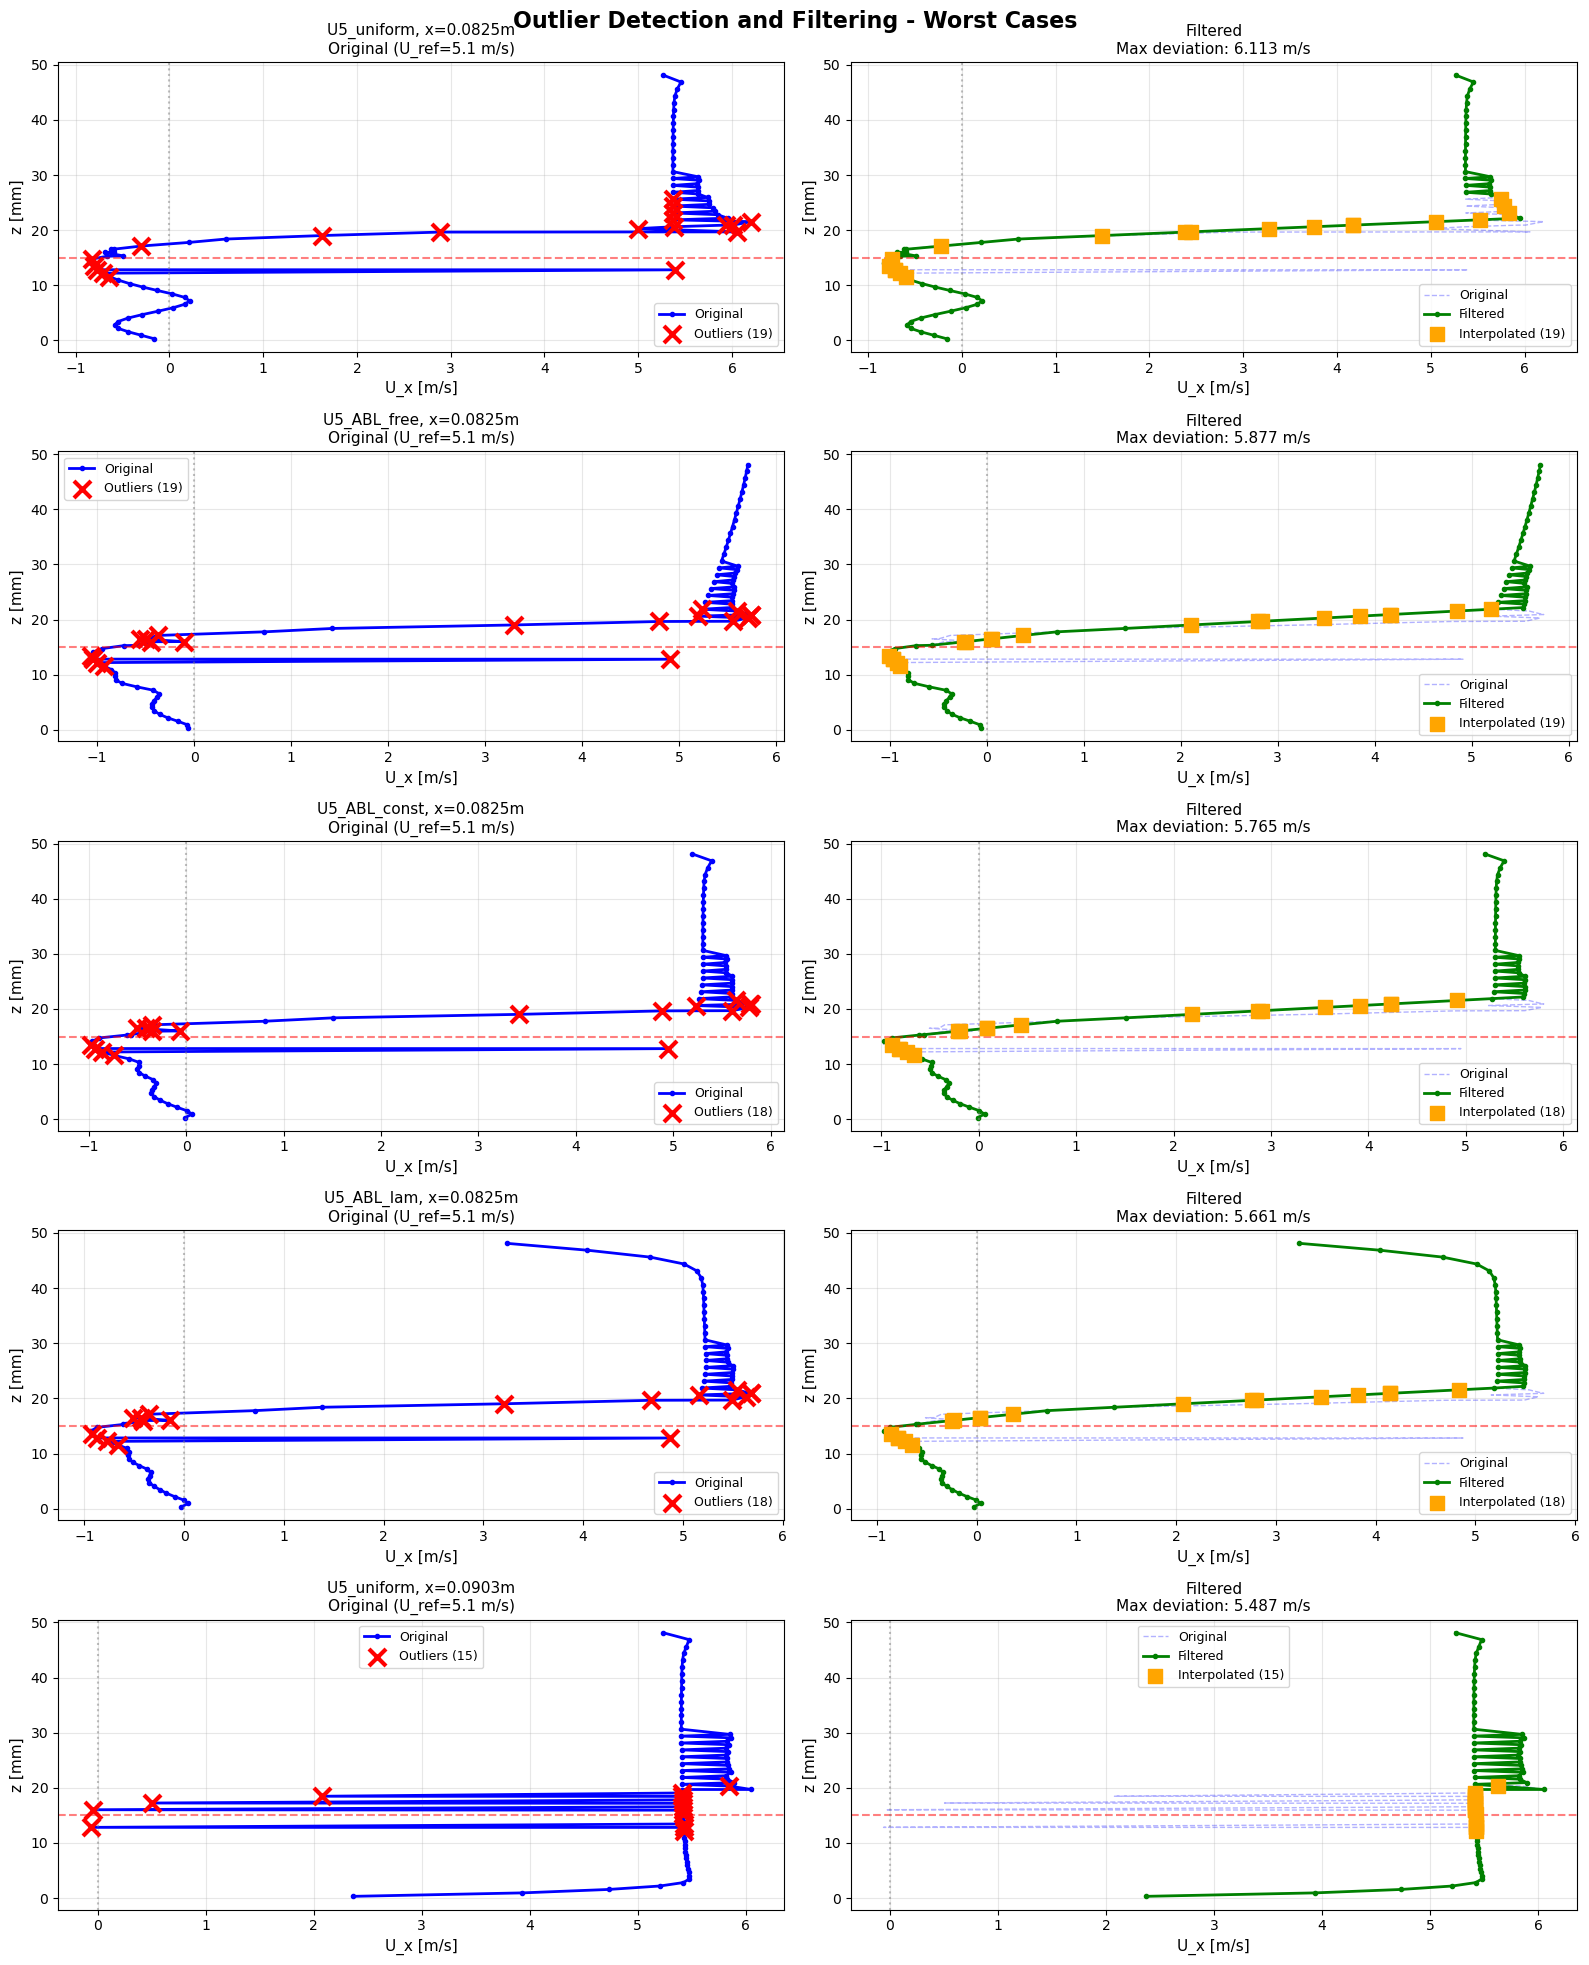

✓ Saved: step1_outlier_filtering.png

SAVING FILTERED DATA
Output: /home/vita/ML/DACI/Multi_Case_CFD/data/processed/all_cases_data.pkl
✓ Saved filtered data successfully!
  File size: 0.23 MB

Saving filtering report: /home/vita/ML/DACI/Multi_Case_CFD/data/processed/outlier_filtering_report.pkl
✓ Saved filtering report!


FILTERED DATA SUMMARY
Total cases: 8
Total profiles: 88
Total data points: 5,432
Average points per profile: 62

--------------------------------------------------------------------------------
Case ID         U_ref    Profile         N_profiles   N_points  
--------------------------------------------------------------------------------
U1_uniform      1.0      Uniform         11           679       
U1_ABL_const    1.0      ABL+constant    11           679       
U1_ABL_lam      1.0      ABL+laminar     11           679       
U1_ABL_free     1.0      ABL+free        11           679       
U5_uniform      5.1      Uniform         11           679       
U5_ABL_cons

In [30]:
# ============================================
# MAIN EXECUTION
# ============================================
MODE = 'filter'


if __name__ == "__main__":
    
    print("\n" + "="*80)
    print(" "*20 + "STEP 1: DATA LOADING & CLEANING")
    print("="*80)
    print(f"EXECUTION MODE: {MODE.upper()}")
    print("="*80 + "\n")
    
    # ========================================================================
    # MODE: LOAD - Extract raw data from OpenFOAM
    # ========================================================================
    
    if MODE in ['load', 'both']:
        print("\n" + "="*80)
        print("MODE: LOADING RAW DATA")
        print("="*80 + "\n")
        
        # Load raw data from OpenFOAM
        all_cases_data = load_all_cases()
        
        # Save raw data
        print("="*80)
        print("SAVING RAW DATA")
        print("="*80)
        print(f"Output: {RAW_DATA_FILE}")
        
        with open(RAW_DATA_FILE, 'wb') as f:
            pickle.dump(all_cases_data, f)
        
        print(f"✓ Saved raw data successfully!")
        print(f"  File size: {os.path.getsize(RAW_DATA_FILE) / 1024 / 1024:.2f} MB")
        print("="*80 + "\n")
        
        # Print summary
        print_data_summary(all_cases_data, "RAW DATA SUMMARY")
        
        if MODE == 'load':
            print("\n" + "="*80)
            print("✓ LOADING COMPLETE!")
            print("="*80)
            print(f"\nRaw data saved to: {RAW_DATA_FILE}")
            print(f"\nNext steps:")
            print(f"  1. Inspect the raw data")
            print(f"  2. Change MODE = 'filter' to apply outlier filtering")
            print(f"  3. Re-run this script")
            print("="*80 + "\n")
    
    # ========================================================================
    # MODE: FILTER - Apply filtering to previously loaded raw data
    # ========================================================================
    
    if MODE in ['filter', 'both']:
        print("\n" + "="*80)
        print("MODE: APPLYING OUTLIER FILTERING")
        print("="*80 + "\n")
        
        # Load raw data if not already loaded
        if MODE == 'filter':
            if not os.path.exists(RAW_DATA_FILE):
                print(f"ERROR: Raw data file not found: {RAW_DATA_FILE}")
                print(f"Please run with MODE='load' first!")
                sys.exit(1)
            
            print(f"Loading raw data from: {RAW_DATA_FILE}")
            with open(RAW_DATA_FILE, 'rb') as f:
                all_cases_data = pickle.load(f)
            print(f"✓ Loaded {len(all_cases_data)} cases")
            print()
        
        # Apply filtering
#         filtering_report = apply_outlier_filtering(all_cases_data)
        all_cases_data, filtering_report = apply_outlier_filtering(all_cases_data)
        
        # Create visualization
        create_outlier_visualization(filtering_report, FILTERING_VIZ_FILE)
        
        # Save filtered data
        print("\n" + "="*80)
        print("SAVING FILTERED DATA")
        print("="*80)
        print(f"Output: {FILTERED_DATA_FILE}")
        
        with open(FILTERED_DATA_FILE, 'wb') as f:
            pickle.dump(all_cases_data, f)
        
        print(f"✓ Saved filtered data successfully!")
        print(f"  File size: {os.path.getsize(FILTERED_DATA_FILE) / 1024 / 1024:.2f} MB")
        
        # Save filtering report
        print(f"\nSaving filtering report: {FILTERING_REPORT_FILE}")
        with open(FILTERING_REPORT_FILE, 'wb') as f:
            pickle.dump(filtering_report, f)
        print(f"✓ Saved filtering report!")
        
        print("="*80 + "\n")
        
        # Print summary
        print_data_summary(all_cases_data, "FILTERED DATA SUMMARY")
        
        print("\n" + "="*80)
        print("FILTERING STATISTICS")
        print("="*80)
        print(f"Profiles checked: {filtering_report['total_profiles_checked']}")
        print(f"Profiles with outliers: {filtering_report['total_profiles_with_outliers']}")
        print(f"Total outliers filtered: {filtering_report['total_outliers']}")
        print(f"Outlier rate: {filtering_report['outlier_rate_percent']:.2f}%")
        print("="*80 + "\n")
        
        print("\n" + "="*80)
        print("✓ FILTERING COMPLETE!")
        print("="*80)
        print(f"\nOutput files:")
        print(f"  • {FILTERED_DATA_FILE}")
        print(f"  • {FILTERING_REPORT_FILE}")
        print(f"  • {FILTERING_VIZ_FILE}")
        print("="*80 + "\n")